Original fitness as -SDD in a scale of -40 to 0

In [1]:
import multiprocessing
multiprocessing.set_start_method("spawn", force=True)

import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold

# Project root
PROJECT_ROOT = Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import sys
from pathlib import Path

# Find project root automatically
PROJECT_ROOT = Path.cwd().parents[1]

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees


In [3]:
from core.metrics import evaluate_tree_new
from evolution.encode_decode import decode
from evolution.genetic_DT_GA_Multi import evolve_trees, _load_dataset_csv

In [4]:
def eval_gene_on_dataset(gene, X, y, k=5, seed=123):

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)

    scores = []

    for tr, te in skf.split(X, y):

        algo = decode(gene)
        algo.fit(X[tr], y[tr])

        m = evaluate_tree_new(algo, X[te], y[te])
        scores.append(m["f1"])

    return np.array(scores)

In [5]:
random.seed(42)

data_path = PROJECT_ROOT / "data"

# (15)
datasets = {
    "abalone": data_path / "abalone.csv",
    "anneal": data_path / "anneal.csv",
    "arrhythmia": data_path / "arrhythmia.csv",
    "bridges": data_path / "bridges_version1.csv",
    "balance_scale": data_path / "balance_scale.csv",
    "car": data_path / "car.csv",
    "cylinder_bands": data_path / "cylinder_bands.csv",
    "glass": data_path / "glass.csv",
    "heart_disease": data_path / "heart_disease.csv",
    "ionosphere": data_path / "ionosphere.csv",
    "semeion": data_path / "semeion.csv",
    "sonar": data_path / "sonar.csv",
    "tic_tac_toe": data_path / "tic_tac_toe.csv",
    "breast_cancer": data_path / "breast_cancer.csv",
    "wine_red": data_path / "winequality_red.csv",
}

# (5)
unseen_datasets = {
    "iris": data_path / "iris.csv",
    "haberman": data_path / "haberman.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv",
}

target_cols = {name: None for name in list(datasets.keys()) + list(unseen_datasets.keys())}

In [6]:
mu = 25
lambd = 25
generations = 30

print("Starting Evolutionary Process...")
print(f"Experiment with mu={mu}, lambda={lambd} for {generations} generations.")
print("Training datasets:", list(datasets.keys()))

Starting Evolutionary Process...
Experiment with mu=25, lambda=25 for 30 generations.
Training datasets: ['abalone', 'anneal', 'arrhythmia', 'bridges', 'balance_scale', 'car', 'cylinder_bands', 'glass', 'heart_disease', 'ionosphere', 'semeion', 'sonar', 'tic_tac_toe', 'breast_cancer', 'wine_red']


In [7]:
timestamp = time.strftime("%Y%m%d_%H%M")

results_dir = Path(
    r"C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs"
)

results_dir.mkdir(parents=True, exist_ok=True)

print("Figures will be saved in:", results_dir)

Figures will be saved in: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs


In [8]:
evo_t0 = time.time()

best_gene, best_fit, history, fitness_rank_history, generalization_history, generalization_sdd_history = evolve_trees(
    datasets,
    unseen_datasets,
    target_cols=target_cols,
    mu=mu,
    lambd=lambd,
    generations=generations)

evo_tf = time.time()


# Tiempo total
total_time = evo_tf - evo_t0
total_minutes = total_time / 60
total_hours = total_time / 3600

# Tiempo promedio por generación
time_per_gen = total_time / generations

print("\n ===== Evolution Summary =====")
print(f"Total time: {total_time:.2f} seconds")
print(f"Total time: {total_minutes:.2f} minutes")
print(f"Total time: {total_hours:.2f} hours")
print(f"Avg time per generation: {time_per_gen:.2f} seconds")

print("\n ===== Results =====")
print("Best gene:", best_gene)
print("Fitness (mean - SDD):", best_fit)


[Evaluation] 25 genes | 15 datasets | 5 folds | workers=18 | timeout=900s

[Progress] 1/25 [OK] gene=[6, 4, 20, 2, 1, 0, 4, 10] fitness=-40.8294 SDD=40.8294 total=389.01s pid=1272
  dataset mean F1 | best=0.3967 worst=0.0101 avg=0.1908
  xi values=[195.9959, 141.0139, 179.4787, 173.4784, 175.0, 131.6963, 92.7846, 157.444, 150.7331, 87.6395, 192.8291, 96.7465, 86.6969, 86.3821, 161.5968]
  - abalone              F1 mean=0.0101 best=0.0106 worst=0.0095 folds=[0.0095, 0.0098, 0.0106, 0.0106, 0.0101]
    time total=0.70s decode=0.00s fit=0.51s metrics=0.17s | depth=0.00 nodes=1.00
  - anneal               F1 mean=0.1730 best=0.1730 worst=0.1729 folds=[0.173, 0.173, 0.173, 0.1729, 0.1729]
    time total=0.79s decode=0.00s fit=0.67s metrics=0.08s | depth=0.40 nodes=1.80
  - arrhythmia           F1 mean=0.0541 best=0.0542 worst=0.0539 folds=[0.0539, 0.0542]
    time total=1.84s decode=0.00s fit=1.75s metrics=0.04s | depth=0.00 nodes=1.00
  - bridges              F1 mean=0.0710 best=0.0882 wo

In [9]:
# Report generalization across datasets
for name, dataset_path in datasets.items():
    target_col = None if target_cols is None else target_cols.get(name, None)

    X, y = _load_dataset_csv(dataset_path, target_col=target_col)
    scores = eval_gene_on_dataset(best_gene, X, y, k=5)

    print(f"{name}: mean F1={scores.mean():.4f}, std F1={scores.std():.4f}, folds={scores}")

c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


abalone: mean F1=0.0124, std F1=0.0004, folds=[0.01180698 0.01232033 0.01289358 0.01281332 0.01233299]
anneal: mean F1=0.1730, std F1=0.0001, folds=[0.17304965 0.17304965 0.17304965 0.17285714 0.17285714]


c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(


arrhythmia: mean F1=0.0597, std F1=0.0022, folds=[0.05833333 0.05833333 0.058753   0.058753   0.06409418]
bridges: mean F1=0.0884, std F1=0.0098, folds=[0.08294931 0.07619048 0.08294931 0.1        0.1       ]


c:\Users\sarah\anaconda3\envs\EvoML\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


balance_scale: mean F1=0.0667, std F1=0.0000, folds=[0.06666667 0.06666667 0.06666667 0.06666667 0.06666667]
car: mean F1=0.2059, std F1=0.0002, folds=[0.20578231 0.20578231 0.20578231 0.20613288 0.20613288]
cylinder_bands: mean F1=0.3662, std F1=0.0018, folds=[0.36470588 0.36470588 0.36470588 0.36842105 0.36842105]
glass: mean F1=0.1303, std F1=0.0297, folds=[0.14380081 0.1125     0.1375     0.1727064  0.08484848]
heart_disease: mean F1=0.1405, std F1=0.0009, folds=[0.14042553 0.14042553 0.14042553 0.14193548 0.13913043]
ionosphere: mean F1=0.3906, std F1=0.0013, folds=[0.38793103 0.39130435 0.39130435 0.39130435 0.39130435]
semeion: mean F1=0.0183, std F1=0.0000, folds=[0.01823362 0.01823362 0.01823362 0.01828571 0.01828571]
sonar: mean F1=0.3480, std F1=0.0038, folds=[0.34375    0.34375    0.35384615 0.34920635 0.34920635]
tic_tac_toe: mean F1=0.3952, std F1=0.0008, folds=[0.39622642 0.39432177 0.39432177 0.39556962 0.39556962]
breast_cancer: mean F1=0.2714, std F1=0.0021, folds=[0.

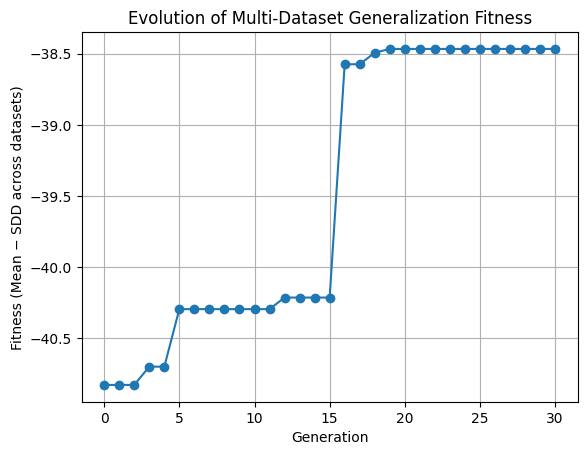

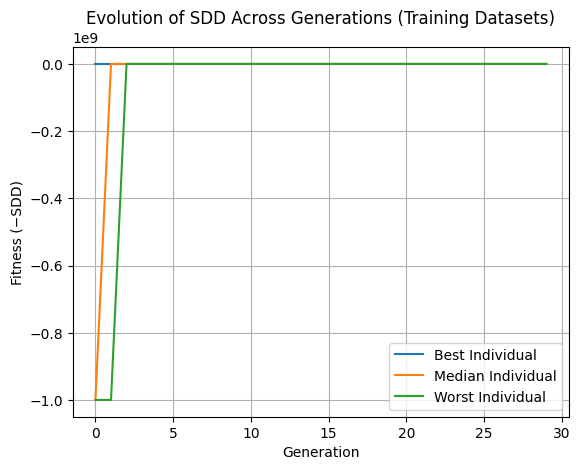

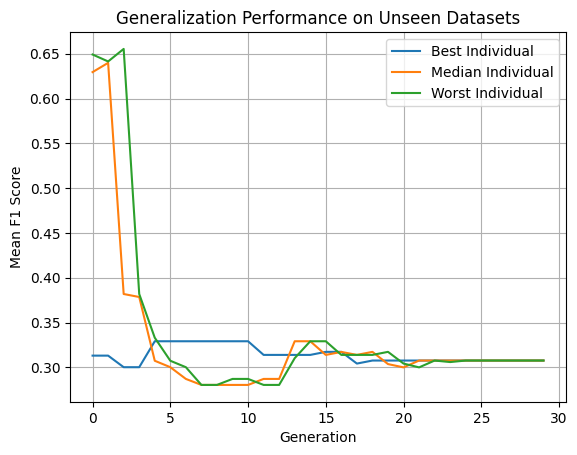

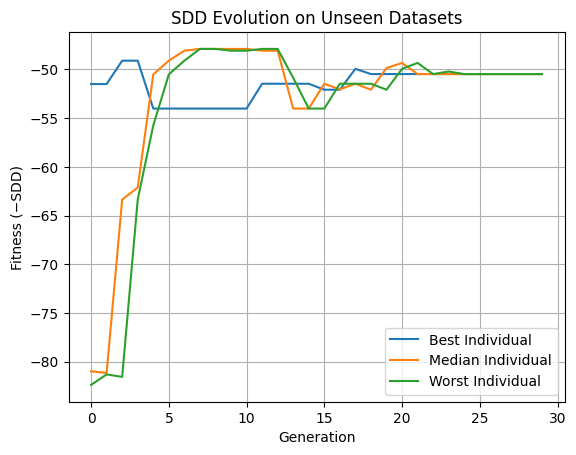

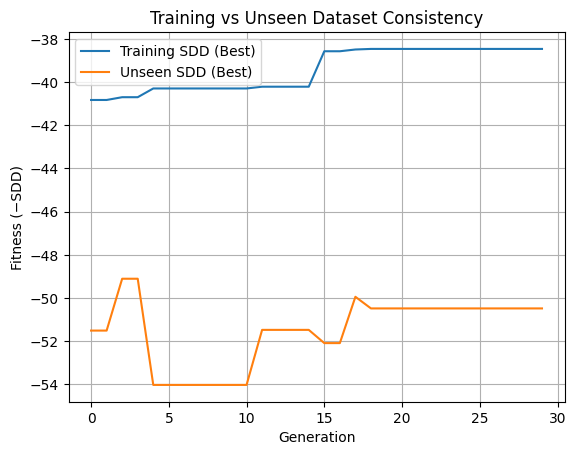

In [10]:
# Graph 1 — Best Fitness Evolution
fig = plt.figure()

plt.plot(history, marker="o")

plt.title("Evolution of Multi-Dataset Generalization Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness (Mean − SDD across datasets)")
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "fitness_evolution.png", dpi=300)



# Graph 2 — Training SDD Evolution
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Best Individual")
plt.plot(fitness_rank_history["median"], label="Median Individual")
plt.plot(fitness_rank_history["worst"], label="Worst Individual")

plt.title("Evolution of SDD Across Generations (Training Datasets)")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_sdd.png", dpi=300)



# Graph 3 — Generalization F1
fig = plt.figure()

plt.plot(generalization_history["best"], label="Best Individual")
plt.plot(generalization_history["median"], label="Median Individual")
plt.plot(generalization_history["worst"], label="Worst Individual")

plt.title("Generalization Performance on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Mean F1 Score")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "generalization_f1.png", dpi=300)



# Graph 4 — Unseen Dataset SDD
fig = plt.figure()

plt.plot(generalization_sdd_history["best"], label="Best Individual")
plt.plot(generalization_sdd_history["median"], label="Median Individual")
plt.plot(generalization_sdd_history["worst"], label="Worst Individual")

plt.title("SDD Evolution on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)

#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "unseen_sdd.png", dpi=300)



# Graph 5 — Training vs Unseen SDD
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Training SDD (Best)")
plt.plot(generalization_sdd_history["best"], label="Unseen SDD (Best)")

plt.title("Training vs Unseen Dataset Consistency")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_vs_unseen_sdd.png", dpi=300)

plt.show()